# 01 — Esplorazione del dataset

Il dataset pulito (`data/processed/dataset.parquet`) contiene una riga per ogni ora dal 1° novembre 2015 al 3 febbraio 2018. Qui si guarda com'è fatto, prima di costruire i modelli di previsione.

Per rigenerarlo: `python -m microgrid.data` e poi `python -m microgrid.dataset`.

Tutte le analisi usano l'ora locale di Costanza e solo i **giorni validi**, cioè quelli senza buchi lunghi nelle misure del carico.

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from microgrid.config import load_config
from microgrid.dataset import load_dataset, local_index
from microgrid.plotting import COLORS, TEXT_SECONDARY, apply_style

apply_style()
config = load_config()
data = load_dataset(config)
data.index = local_index(data.index, config)
valid = data[data["valid_day"]]

days = data["valid_day"].groupby(data.index.date).first()
print(f"Ore: {len(data)}   giorni: {len(days)}   giorni validi: {int(days.sum())}")
print(f"Valori mancanti nei giorni validi: {int(valid.isna().sum().sum())}")
data.describe().T[["mean", "min", "max"]].round(3)

Ore: 19824   giorni: 826   giorni validi: 776
Valori mancanti nei giorni validi: 0


,mean,min,max
load_kw,8.724,0.986,70.816
pv_kw,11.831,0.000,88.183
temperature_c,9.759,-12.600,31.300
radiation_w_m2,131.098,0.000,912.000
cloud_cover_pct,66.124,0.000,100.000
price_eur_kwh,0.031,-0.130,0.164
carbon_kg_kwh,0.415,0.154,0.594


## 1. Periodo, giorni esclusi e divisione dei dati

Il carico medio giornaliero su tutto il periodo. I giorni non validi sono quelli in cui il fornitore dei dati ha interpolato le letture di contatore per più di 6 ore: l'energia totale è corretta, l'andamento orario no. Restano nel file, marcati con `valid_day = False`.

La divisione è in ordine temporale e per giorni interi: primi 70% dei giorni per l'addestramento, 15% per la validazione, ultimi 15% per il test.

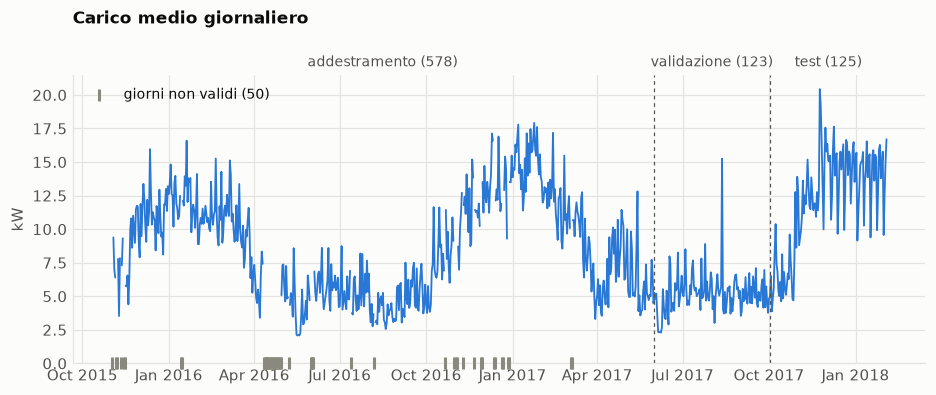

              ore  ore_valide
split                        
train       13871       12671
validation   2952        2952
test         3001        3001


In [2]:
daily = data["load_kw"].resample("D").mean()
daily_valid = data["valid_day"].resample("D").first().astype(bool)
split = data["split"].resample("D").first()

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(daily.index, daily.where(daily_valid), color=COLORS["load"], linewidth=1.2)
invalid = daily[~daily_valid]
ax.scatter(invalid.index, np.zeros(len(invalid)), marker="|", s=60, color=COLORS["muted"],
           label=f"giorni non validi ({len(invalid)})", clip_on=False, zorder=3)
for name, label in [("train", "addestramento"), ("validation", "validazione"), ("test", "test")]:
    chunk = split[split == name]
    first, last = chunk.index[0], chunk.index[-1]
    if name != "train":
        ax.axvline(first, color=TEXT_SECONDARY, linewidth=0.8, linestyle=(0, (3, 3)))
    ax.annotate(f"{label} ({len(chunk)})", (first + (last - first) / 2, 1.02),
                xycoords=("data", "axes fraction"), ha="center", va="bottom", color=TEXT_SECONDARY, fontsize=9)
ax.set_ylim(0, None)
ax.set_ylabel("kW")
ax.set_title("Carico medio giornaliero", pad=34)
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(loc="upper left", fontsize=9)
plt.show()

print(data.groupby("split", sort=False)["valid_day"].agg(ore="size", ore_valide="sum"))

**Cosa si vede**

- Su 826 giorni, 50 non sono validi. Sono tutti nei dati di addestramento; 19 cadono in aprile 2016.
- Validazione e test non hanno giorni esclusi.
- Il test set va dal 2 ottobre 2017 al 3 febbraio 2018: copre solo autunno e inverno. Lì il carico medio è 12,1 kW e il fotovoltaico 7,2 kW, contro 8,7 kW e 11,7 kW nell'addestramento. I risultati finali descriveranno quindi la stagione meno favorevole al fotovoltaico, non un anno intero.
- La validazione (giugno – 1° ottobre 2017) è invece tutta estiva.

## 2. Profilo giornaliero e settimanale del carico

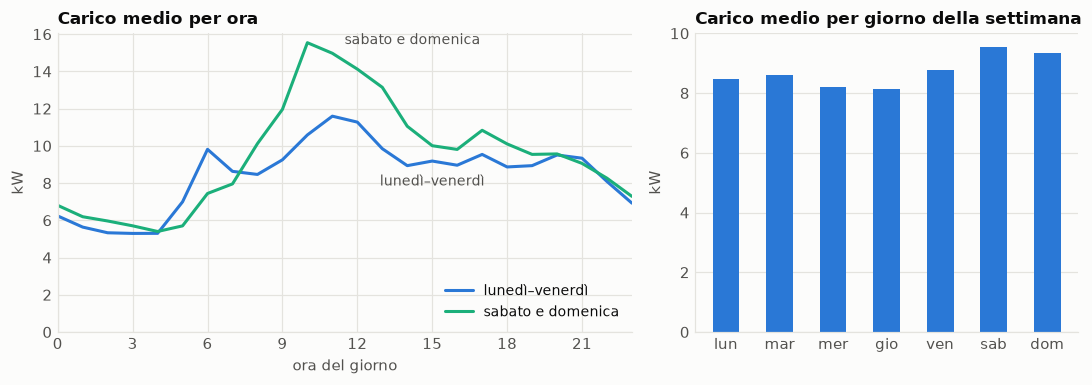

utc_timestamp       0    1    2    3    4    5    6    7     8     9     10    11    12    13    14    15   16    17    18   19   20   21   22   23
lunedì–venerdì     6.2  5.6  5.3  5.3  5.3  7.0  9.8  8.6   8.5   9.2  10.6  11.6  11.3   9.8   8.9   9.2  9.0   9.5   8.9  8.9  9.5  9.3  8.1  6.9
sabato e domenica  6.8  6.2  6.0  5.7  5.4  5.7  7.4  8.0  10.1  12.0  15.5  15.0  14.1  13.1  11.1  10.0  9.8  10.8  10.1  9.5  9.6  9.1  8.3  7.3

Media per giorno della settimana: [8.48, 8.6, 8.19, 8.13, 8.78, 9.53, 9.35]


In [3]:
weekend = valid.index.day_of_week >= 5
profile = pd.DataFrame({
    "lunedì–venerdì": valid.loc[~weekend, "load_kw"].groupby(valid.index[~weekend].hour).mean(),
    "sabato e domenica": valid.loc[weekend, "load_kw"].groupby(valid.index[weekend].hour).mean(),
})
by_day = valid["load_kw"].groupby(valid.index.day_of_week).mean()

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [3, 2]})
for column, color in zip(profile.columns, [COLORS["load"], COLORS["alt"]]):
    left.plot(profile.index, profile[column], color=color, label=column)
left.annotate("lunedì–venerdì", (15, profile.iloc[15, 0]), xytext=(0, -16), textcoords="offset points",
              ha="center", color=TEXT_SECONDARY, fontsize=9)
left.annotate("sabato e domenica", (11, profile.iloc[11, 1]), xytext=(8, 6), textcoords="offset points",
              color=TEXT_SECONDARY, fontsize=9)
left.set_xticks(range(0, 24, 3))
left.set_xlim(0, 23)
left.set_ylim(0, None)
left.set_xlabel("ora del giorno")
left.set_ylabel("kW")
left.set_title("Carico medio per ora")
left.legend(loc="lower right", fontsize=9)

right.bar(by_day.index, by_day.values, width=0.5, color=COLORS["load"])
right.set_xticks(range(7), ["lun", "mar", "mer", "gio", "ven", "sab", "dom"])
right.set_ylabel("kW")
right.set_title("Carico medio per giorno della settimana")
right.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

print(profile.round(1).T.to_string())
print()
print("Media per giorno della settimana:", by_day.round(2).tolist())

**Cosa si vede**

- Di notte il carico scende a circa 5 kW. Nei giorni feriali c'è un primo picco alle 6 (circa 10 kW) e un secondo fra le 10 e le 12 (circa 11,5 kW); la sera resta attorno a 9 kW, senza un picco netto.
- Nel fine settimana la mattina parte più tardi e il picco è più alto: 15,5 kW alle 10.
- Sabato e domenica consumano in media circa il 10% in più dei giorni feriali.
- Il carico viene da due sole abitazioni, una delle quali ha pompa di calore e auto elettrica: il profilo è meno regolare di quello di un quartiere intero.

## 3. Stagionalità di carico e fotovoltaico

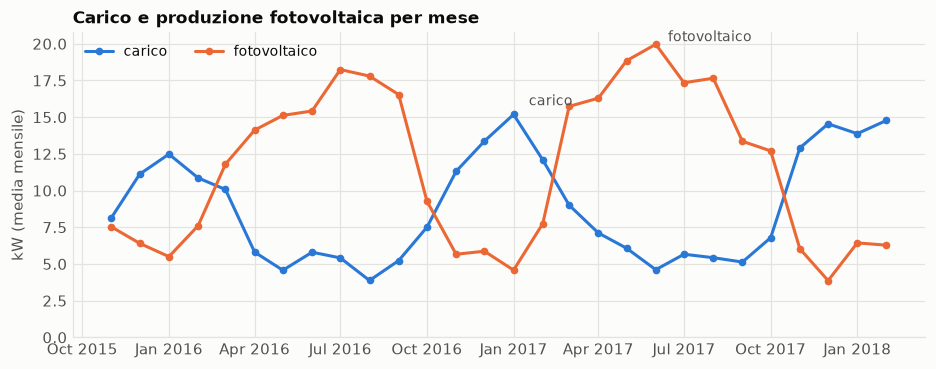

2016, giorni validi (324): carico 62.4 MWh, fotovoltaico 93.2 MWh
  surplus orario 69.0 MWh, deficit orario 38.2 MWh
  ore con fotovoltaico > carico: 32%
utc_timestamp  2015-11-01  2015-12-01  2016-01-01  2016-02-01  2016-03-01  2016-04-01  2016-05-01  2016-06-01  2016-07-01  2016-08-01  2016-09-01  2016-10-01  2016-11-01  2016-12-01  2017-01-01  2017-02-01  2017-03-01  2017-04-01  2017-05-01  2017-06-01  2017-07-01  2017-08-01  2017-09-01  2017-10-01  2017-11-01  2017-12-01  2018-01-01  2018-02-01
load_kw               8.2        11.1        12.5        10.9        10.1         5.8         4.6         5.8         5.4         3.9         5.2         7.5        11.3        13.4        15.2        12.1         9.0         7.1         6.1         4.6         5.7         5.4         5.1         6.8        12.9        14.5        13.9        14.8
pv_kw                 7.5         6.4         5.5         7.6        11.8        14.1        15.1        15.4        18.2        17.8        16.5 

In [4]:
monthly = valid[["load_kw", "pv_kw"]].groupby(valid.index.tz_localize(None).to_period("M")).mean()
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(monthly.index, monthly["load_kw"], color=COLORS["load"], marker="o", markersize=4, label="carico")
ax.plot(monthly.index, monthly["pv_kw"], color=COLORS["pv"], marker="o", markersize=4, label="fotovoltaico")
ax.annotate("carico", (monthly.index[14], monthly["load_kw"].iloc[14]), xytext=(10, 6), textcoords="offset points",
            color=TEXT_SECONDARY, fontsize=9)
ax.annotate("fotovoltaico", (monthly.index[19], monthly["pv_kw"].iloc[19]), xytext=(8, 2), textcoords="offset points",
            color=TEXT_SECONDARY, fontsize=9)
ax.set_ylim(0, None)
ax.set_ylabel("kW (media mensile)")
ax.set_title("Carico e produzione fotovoltaica per mese")
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(loc="upper left", ncols=2, fontsize=9)
plt.show()

year = valid.loc["2016"]
surplus = (year["pv_kw"] - year["load_kw"]).clip(lower=0).sum() / 1000
deficit = (year["load_kw"] - year["pv_kw"]).clip(lower=0).sum() / 1000
print(f"2016, giorni validi ({year.index.normalize().nunique()}): carico {year['load_kw'].sum() / 1000:.1f} MWh, "
      f"fotovoltaico {year['pv_kw'].sum() / 1000:.1f} MWh")
print(f"  surplus orario {surplus:.1f} MWh, deficit orario {deficit:.1f} MWh")
print(f"  ore con fotovoltaico > carico: {(year['pv_kw'] > year['load_kw']).mean():.0%}")
print(monthly.round(1).T.to_string())

**Cosa si vede**

- Carico e fotovoltaico hanno stagionalità opposte. Il carico va da 4–6 kW in estate a 11–15 kW in inverno; il fotovoltaico da 15–20 kW in estate a 4–6 kW in inverno.
- Nei giorni validi del 2016 il fotovoltaico produce più di quanto si consuma (93 MWh contro 62 MWh), ma non nelle stesse ore: restano 69 MWh di surplus e 38 MWh di deficit.
- Il fotovoltaico supera il carico solo nel 32% delle ore.
- In estate la batteria ha molto surplus da spostare dal giorno alla notte. In inverno il surplus è poco: lì il suo valore dipende soprattutto dalle differenze di prezzo.

## 4. Carico e temperatura

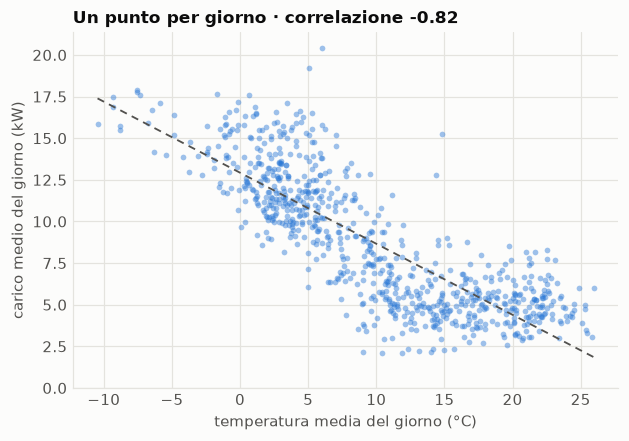

Correlazione giornaliera: -0.819   pendenza: -0.43 kW per °C
Correlazione oraria:      -0.461
Carico medio sotto 5 °C: 12.8 kW   sopra 15 °C: 5.1 kW


In [5]:
per_day = valid[["load_kw", "temperature_c"]].resample("D").mean().dropna()
slope, intercept = np.polyfit(per_day["temperature_c"], per_day["load_kw"], 1)
correlation = per_day["load_kw"].corr(per_day["temperature_c"])

fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.scatter(per_day["temperature_c"], per_day["load_kw"], s=14, color=COLORS["load"], alpha=0.45, linewidths=0)
temperatures = np.array([per_day["temperature_c"].min(), per_day["temperature_c"].max()])
ax.plot(temperatures, intercept + slope * temperatures, color=TEXT_SECONDARY, linewidth=1.2, linestyle=(0, (4, 3)))
ax.set_ylim(0, None)
ax.set_xlabel("temperatura media del giorno (°C)")
ax.set_ylabel("carico medio del giorno (kW)")
ax.set_title(f"Un punto per giorno · correlazione {correlation:.2f}")
plt.show()

print(f"Correlazione giornaliera: {correlation:.3f}   pendenza: {slope:.2f} kW per °C")
print(f"Correlazione oraria:      {valid['load_kw'].corr(valid['temperature_c']):.3f}")
cold = per_day[per_day["temperature_c"] < 5]["load_kw"]
warm = per_day[per_day["temperature_c"] > 15]["load_kw"]
print(f"Carico medio sotto 5 °C: {cold.mean():.1f} kW   sopra 15 °C: {warm.mean():.1f} kW")

**Cosa si vede**

- La correlazione fra carico medio e temperatura media del giorno è −0,82: ogni grado in meno aggiunge circa 0,43 kW.
- Sotto i 5 °C il carico medio è 12,8 kW, sopra i 15 °C è 5,1 kW.
- La relazione non è una retta: sopra i 12–15 °C il carico smette di scendere. Un modello ad alberi la coglie senza trasformazioni.
- Ora per ora la correlazione è più debole (−0,46): la temperatura spiega il livello del giorno, non l'andamento dentro la giornata.

## 5. Prezzo ed intensità di carbonio nelle 24 ore

La linea è la media per ora del giorno, la fascia va dal 10° al 90° percentile. Sono due grandezze con unità diverse, quindi due grafici separati.

Prezzo day-ahead: minimo medio alle 3 (21), massimo medio alle 18 (41)
Intensità di carbonio della rete: minimo medio alle 13 (377), massimo medio alle 20 (443)


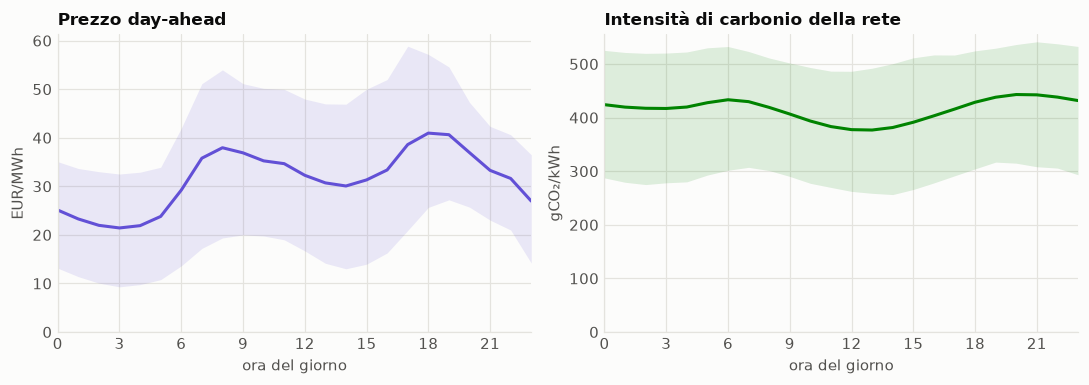

Correlazione oraria prezzo–intensità di carbonio: 0.62
Ore con prezzo negativo: 316
Differenza fra prezzo massimo e minimo nello stesso giorno: mediana 23 EUR/MWh


In [6]:
def hourly_band(series):
    grouped = series.groupby(series.index.hour)
    return grouped.mean(), grouped.quantile(0.10), grouped.quantile(0.90)

panels = [
    ("price_eur_kwh", 1000, "price", "Prezzo day-ahead", "EUR/MWh"),
    ("carbon_kg_kwh", 1000, "carbon", "Intensità di carbonio della rete", "gCO₂/kWh"),
]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, (column, factor, color, title, unit) in zip(axes, panels):
    mean, low, high = hourly_band(data[column] * factor)
    ax.fill_between(mean.index, low, high, color=COLORS[color], alpha=0.12, linewidth=0)
    ax.plot(mean.index, mean, color=COLORS[color])
    ax.set_xticks(range(0, 24, 3))
    ax.set_xlim(0, 23)
    ax.set_ylim(0, None)
    ax.set_xlabel("ora del giorno")
    ax.set_ylabel(unit)
    ax.set_title(title)
    print(f"{title}: minimo medio alle {mean.idxmin()} ({mean.min():.0f}), massimo medio alle {mean.idxmax()} ({mean.max():.0f})")
fig.tight_layout()
plt.show()

print(f"Correlazione oraria prezzo–intensità di carbonio: {data['price_eur_kwh'].corr(data['carbon_kg_kwh']):.2f}")
print(f"Ore con prezzo negativo: {(data['price_eur_kwh'] < 0).sum()}")
daily_spread = (data["price_eur_kwh"] * 1000).resample("D").agg(lambda x: x.max() - x.min())
print(f"Differenza fra prezzo massimo e minimo nello stesso giorno: mediana {daily_spread.median():.0f} EUR/MWh")

**Cosa si vede**

- Il prezzo ha due picchi, alle 8 (38 EUR/MWh) e alle 18 (41 EUR/MWh), e il minimo alle 3 di notte (21 EUR/MWh). Nello stesso giorno la differenza fra massimo e minimo è in mediana di 23 EUR/MWh.
- L'intensità di carbonio è minima alle 13 (377 gCO₂/kWh), quando il solare tedesco produce, e massima alle 20 (443 gCO₂/kWh).
- La fascia dell'intensità di carbonio è molto più larga della variazione della media: conta più il giorno (vento, stagione) dell'ora.
- Prezzo e intensità di carbonio sono correlati (0,62) ma non coincidono: le ore più economiche sono di notte, le più pulite a mezzogiorno. Minimizzare il costo e minimizzare le emissioni portano a piani diversi.
- Ci sono 316 ore con prezzo negativo.

## Conseguenze per le fasi successive

- **Previsione del carico.** Servono la temperatura, l'ora e la distinzione fra giorni feriali e fine settimana. Il carico di due abitazioni è irregolare: la previsione ingenua sarà difficile da battere di molto.
- **Giorni non validi.** Vanno esclusi dai bersagli dell'addestramento e non usati come valori ritardati.
- **Giorni di 23 e 25 ore.** I due cambi d'ora all'anno producono giorni locali più corti o più lunghi: l'ottimizzatore non può assumere 24 ore fisse.
- **Valutazione.** Il test set è solo autunno–inverno. Va detto accanto a ogni risultato.
- **Costo ed emissioni.** I due obiettivi sono in parte in conflitto: il fronte di Pareto ha senso.